# My Question

I want to see ratings by actor, director, studio, etc. I'd like to see if there are correlations, and what has the highest correlation. 

## Data Sets

The data I'm working with comes from [IMDb's Non-Commercial Dataset Page](https://data.imdb.com/non-commercial-datasets/). From this page I'll be using the following datasets: 

### [title.akas.tsv.gz](https://datasets.imdbws.com/title.akas.tsv.gz)

This contains the names of movies for all the regions it was released in. The columns I'll use from this dataset are: 
- titleId (string): A unique alphanumeric identifier
- title (string): the localized title 
- region (string): the region for this version of the title
- isOriginalTitle (boolean): 0 if not the original title, 1 if it *is* the original title

### [title.basics.tsv.gz](https://datasets.imdbws.com/title.basics.tsv.gz)

This containts the names of movies and some basic information about the movie. The columns I'll use from this dataset are: 
- tconst (string): A unique alphanumeric identifier (primary key)
- titleType (string): type or format of the title (differentiating movies from tv shows)
- primaryTitle (string): The popular title of the movie 
- isAdult (boolean): 0 if non-adult title, 1 for adult title
- startYear (YYYY): release data of the movie/show
- runtimeMinutes: movie runtime 
- genres (string array): up to three associated genres

### [title.crew.tsv.gz](https://datasets.imdbws.com/title.crew.tsv.gz)

This contains the directors and writers of a project. The columns I'll use from this dataset are: 
- tconst (string): a unique alphanumeric identifier of movies (primary and foreign key) 
- directors (array of nconsts): directors of a project 
- writers (array of nconsts): writers of a project 

### [title.principals.tsv.gz](https://datasets.imdbws.com/title.principals.tsv.gz)

This contains cast information using tconst as a foreign/primary key. The columns I'll use from this dataset are: 
- tconst (string): unique alphanumeric identifier of movies (foreign key) 
- ordering (int): a unique row indentifier 
- nconst (string): unique alphanumeric identifier of the name/person (foreign key) 
- category (string): the category of job the person was in 
- job (string): specific job title if applicable
- characters (string): the name of the character played if applicable

### [title.ratings.tsv.gz](https://datasets.imdbws.com/title.ratings.tsv.gz)

This contains a rating for every title in the dataset. The columns I'll use from this dataset are: 
- tconst (string): unique alphanumeric identifier (primary and foreign key)
- averageRating: weighted average of all user ratings 
- numVotes: number of votes a title has receieved 

### [name.basics.tsv.gz](https://datasets.imdbws.com/name.basics.tsv.gz)

This contains information of each cast member listed on any project: The columns I'll use from this dataset are: 
- nconst (string): unique alphanumeric identifier of person (foreign and primary key) 
- primaryName (string): the name by which the person is most often credited
- primaryProfession (array of strings): top-3 known professions
- knownForTitles (array of tconsts): titles the person is known for 

## Step 1
First I want to filter out some of this data. There is *a lot* of data here and I want stuff that is relevant to my question. The first thing I'm going to do is use title.akas to find the region the region that I want. I also only want titles that are for the original region. 

In [198]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np 
from scipy.stats import linregress
import seaborn as sns

In [ ]:
try: 
    aka_filter_df = pd.read_csv("data/title_aka_filter.tsv", sep = "\t")
    
except: 
    title_aka_df = pd.read_csv("data/title.akas.tsv", sep = "\t")[['titleId', 'title', 'region', 'isOriginalTitle']]
    mask = (
        (title_aka_df['region'] == 'US') & 
        (title_aka_df['isOriginalTitle'] == 0)
    )
    aka_filter_df = title_aka_df.loc[mask, :]
    aka_filter_df[['titleId', 'title']].to_csv("data/title_aka_filter.tsv", sep = "\t", index=False)

aka_filter_df.head()

### Result
What this gave me back was a list of titles where their original region was not in the US. I will remove all these titles from my final dataset, because I don't care about them (sorry foreign films). 

## Step 2
I want to do some filtering to get the projects I want from title.basics.tsv. I will filter to only titles that are newer than 1980 (just to give me computer a break). And then I'd like to see the distribution of titles. I'm also going to drop any rows with any NA values. 

In [200]:
try: 
    basic_filter_df = pd.read_csv("data/title_basics_filter.tsv", sep = "\t")
    basic_filter_df['startYear'] = pd.to_numeric(basic_filter_df['startYear'], errors= 'coerce')
    basic_filter_df['genres'] = basic_filter_df['genres'].replace("\\N", np.nan)
    basic_filter_df['titleType'] = basic_filter_df['titleType'].replace("\\N", np.nan)
    basic_filter_df['primaryTitle'] = basic_filter_df['primaryTitle'].replace("\\N", np.nan)
    basic_filter_df['isAdult'] = basic_filter_df['isAdult'].replace("\\N", np.nan)
except: 
    title_basics_df = pd.read_csv("data/title.basics.tsv", sep = "\t")[['tconst', 'titleType', 'primaryTitle', 'isAdult', 'startYear', 'runtimeMinutes', 'genres']]
    basic_filter_df = title_basics_df[~title_basics_df['tconst'].isin(aka_filter_df['titleId'])]
    mask = (
        (basic_filter_df['titleType'] == "movie")
        & (pd.to_numeric(basic_filter_df['startYear'], errors='coerce') >= 1980)
        & (basic_filter_df['isAdult'] == 0)
    )
    basic_filter_df = basic_filter_df.loc[mask, :]
    basic_filter_df['runtimeMinutes'] = pd.to_numeric(basic_filter_df['runtimeMinutes'], errors= 'coerce')
    basic_filter_df['startYear'] = pd.to_numeric(basic_filter_df['startYear'], errors= 'coerce')
    basic_filter_df['genres'] = basic_filter_df['genres'].replace("\\N", np.nan)
    basic_filter_df['titleType'] = basic_filter_df['titleType'].replace("\\N", np.nan)
    basic_filter_df['primaryTitle'] = basic_filter_df['primaryTitle'].replace("\\N", np.nan)
    basic_filter_df['isAdult'] = basic_filter_df['isAdult'].replace("\\N", np.nan)
    basic_filter_df.to_csv("data/title_basics_filter.tsv", sep = "\t", index=False)
    
basic_filter_df.head()

,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres
0,tt0011801,movie,Tötet nicht mehr,0,2019,NaN,"Action,Crime"
1,tt0015724,movie,Dama de noche,0,1993,102.0,"Drama,Mystery,Romance"
2,tt0038086,movie,Shiva und die Galgenblume,0,1993,NaN,"Documentary,Thriller"
3,tt0046976,movie,Il figlio dell'uomo,0,2000,NaN,NaN
4,tt0057461,movie,La rosa de los vientos,0,1983,84.0,"Drama,Fantasy"


In [201]:
shape = basic_filter_df.shape
print("Rows:", shape[0])
print("Cols:", shape[1])
print(basic_filter_df.isna().sum())

Rows: 203717
Cols: 7
tconst                0
titleType             0
primaryTitle          0
isAdult               0
startYear             0
runtimeMinutes    58632
genres            24949
dtype: int64


In [202]:
basic_filter_df = basic_filter_df.dropna()
shape = basic_filter_df.shape
print("Rows:", shape[0])
print("Cols:", shape[1])
print(basic_filter_df.isna().sum())

Rows: 133936
Cols: 7
tconst            0
titleType         0
primaryTitle      0
isAdult           0
startYear         0
runtimeMinutes    0
genres            0
dtype: int64


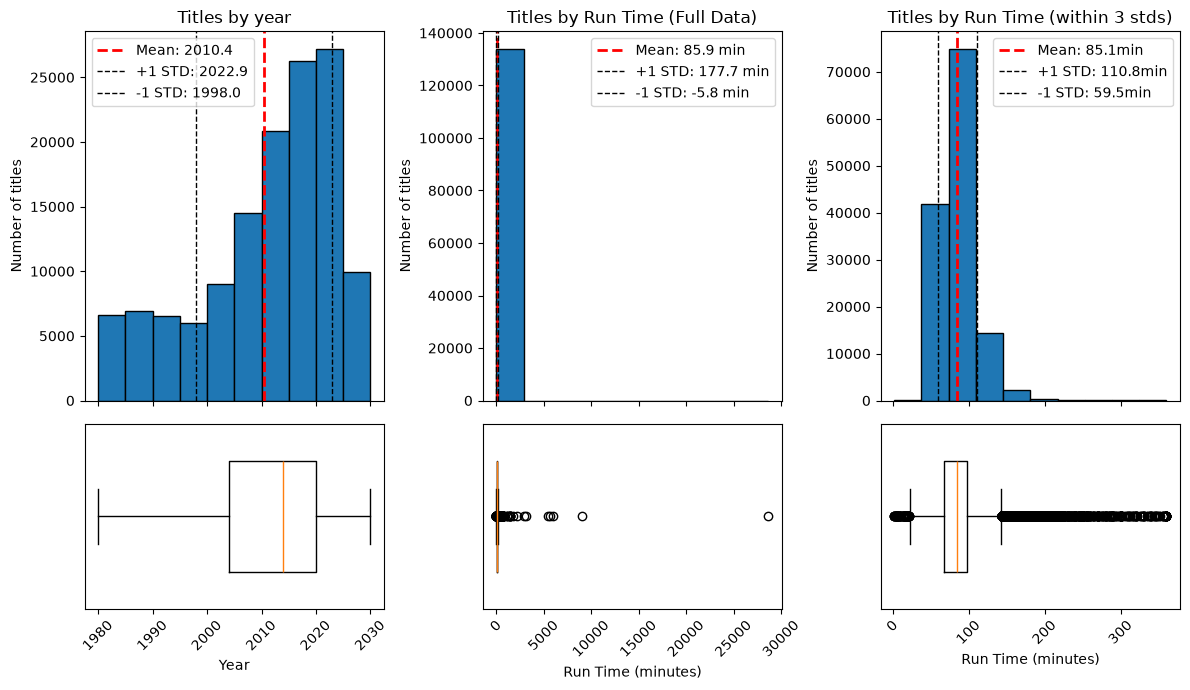

In [203]:
def within_3_std(s, a = 3):
    mean, std = s.mean(), s.std()
    return s[(s - mean).abs() <= a * std]

year_data = basic_filter_df['startYear'].dropna()
runtime_data = basic_filter_df['runtimeMinutes'].dropna()
runtime_data_filt = within_3_std(runtime_data)

plots = [
    (year_data, 'Year', 'Titles by year', ''),
    (runtime_data, 'Run Time (minutes)', 'Titles by Run Time (Full Data)', ' min'),
    (runtime_data_filt, 'Run Time (minutes)', 'Titles by Run Time (within 3 stds)', 'min')
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex='col',
                         gridspec_kw={'height_ratios': [2, 1]})

for col, (data, xlabel, title, unit) in enumerate(plots):
    hist_ax = axes[0, col]
    box_ax = axes[1, col]
    mean, std = data.mean(), data.std()

    # Histogram
    hist_ax.hist(data, bins=10, edgecolor='black')
    hist_ax.axvline(mean, color='red', linestyle='--', linewidth=2,
                    label=f'Mean: {mean:.1f}{unit}')
    hist_ax.axvline(mean + std, color='black', linestyle='--', linewidth=1,
                    label=f'+1 STD: {mean + std:.1f}{unit}')
    hist_ax.axvline(mean - std, color='black', linestyle='--', linewidth=1,
                    label=f'-1 STD: {mean - std:.1f}{unit}')
    hist_ax.set_ylabel('Number of titles')
    hist_ax.set_title(title)
    hist_ax.legend()

    # Boxplot
    box_ax.boxplot(data, orientation='horizontal', widths=0.6)
    box_ax.set_yticks([])
    box_ax.set_xlabel(xlabel)
    box_ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

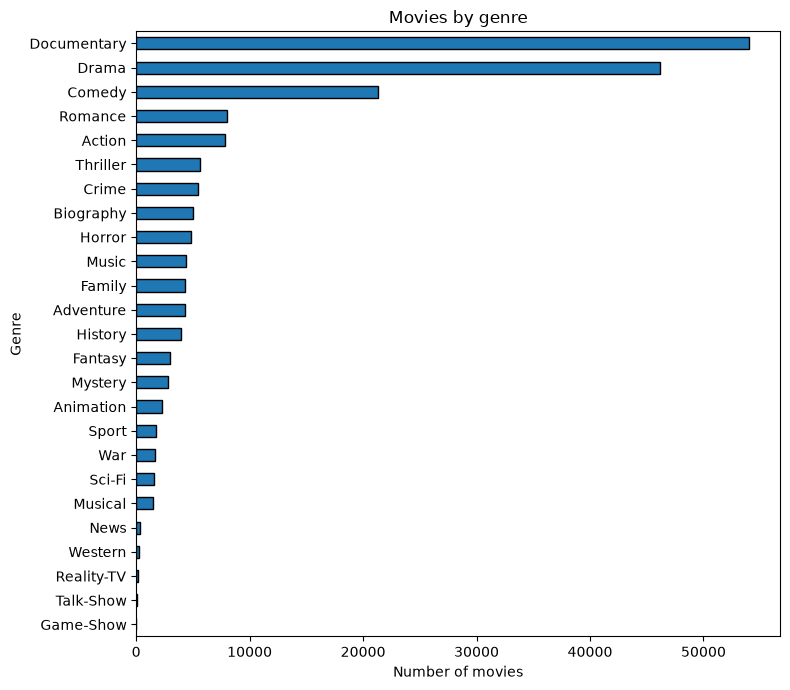

In [204]:
genre_df = basic_filter_df.assign(
    genres=basic_filter_df['genres'].str.split(',')
).explode('genres')

genre_counts = genre_df.groupby('genres')['tconst'].count().sort_values()

ax = genre_counts.plot.barh(figsize=(8, 7), edgecolor='black')
ax.set_xlabel('Number of movies')
ax.set_ylabel('Genre')
ax.set_title('Movies by genre')
plt.tight_layout()
plt.show()

### Result
At first glance it looks like the majority of these movies are Documentaries, Dramas, and Comedies. Most of the movies were made more recently (left skewed data). Another interesting component is s a mean of 85.9 minutes, which is lower than I expected. 

## Step 3

I'm going to merge the title_crew information with the title.basics information. before I do a left merge on tconst I'm gonna drop all the na's. Then I'll do some plots to see what it all looks like. 

In [ ]:
try: 
    crew_filter_df = pd.read_csv("data/title_crew_filter.tsv", sep = "\t")
    shape = crew_filter_df.shape
    print("Filtered DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
    print(crew_filter_df.isna().sum())
except: 
    title_crew_df = pd.read_csv("data/title.crew.tsv", sep = "\t")
    title_crew_df['writers'] = title_crew_df['writers'].replace("\\N", np.nan)
    title_crew_df['directors'] = title_crew_df['directors'].replace("\\N", np.nan)
    title_crew_df['tconst'] = title_crew_df['tconst'].replace("\\N", np.nan)
    shape = title_crew_df.shape
    print("Initial DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
    print(title_crew_df.isna().sum())
    crew_filter_df = title_crew_df.dropna()
    shape = crew_filter_df.shape
    print("\nFiltered DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
    print(crew_filter_df.isna().sum())
    crew_filter_df.to_csv("data/title_crew_filter.tsv", sep = "\t", index = False)

crew_filter_df.head()

Filtered DF
Rows: 5525934
Cols: 3
tconst       0
directors    0
writers      0
dtype: int64


,tconst,directors,writers
0,tt0000003,nm0721526,nm0721526
1,tt0000009,nm0085156,nm0085156
2,tt0000015,nm0721526,nm0721526
3,tt0000036,nm0567363,nm0410331
4,tt0000076,nm0567363,nm0410331


In [206]:
basic_crew_merge = pd.merge(
    basic_filter_df,
    crew_filter_df, 
    how = "inner", 
    on = "tconst", 
    )
shape = basic_crew_merge.shape
print("Rows:", shape[0])
print("Cols:", shape[1])
print(basic_crew_merge.isna().sum())
basic_crew_merge.to_csv("data/title_basic_crew_merge.tsv", sep = "\t", index = False)
basic_crew_merge.head()

Rows: 103924
Cols: 9
tconst            0
titleType         0
primaryTitle      0
isAdult           0
startYear         0
runtimeMinutes    0
genres            0
directors         0
writers           0
dtype: int64


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres,directors,writers
0,tt0015724,movie,Dama de noche,0,1993,102.0,"Drama,Mystery,Romance",nm0529960,"nm0529960,nm1597742"
1,tt0057461,movie,La rosa de los vientos,0,1983,84.0,"Drama,Fantasy",nm0350099,"nm1104994,nm0350099,nm0489739"
2,tt0065108,movie,Tolko tri nochi,0,1989,82.0,"Drama,Romance",nm0947248,nm0097469
3,tt0065188,movie,"Vojtech, receny sirotek",0,1990,80.0,Drama,nm0878702,"nm0434141,nm0815785,nm0878702"
4,tt0065530,movie,Le cercle des passions,0,1983,108.0,Drama,nm0195327,"nm0094669,nm0379586,nm0195327"


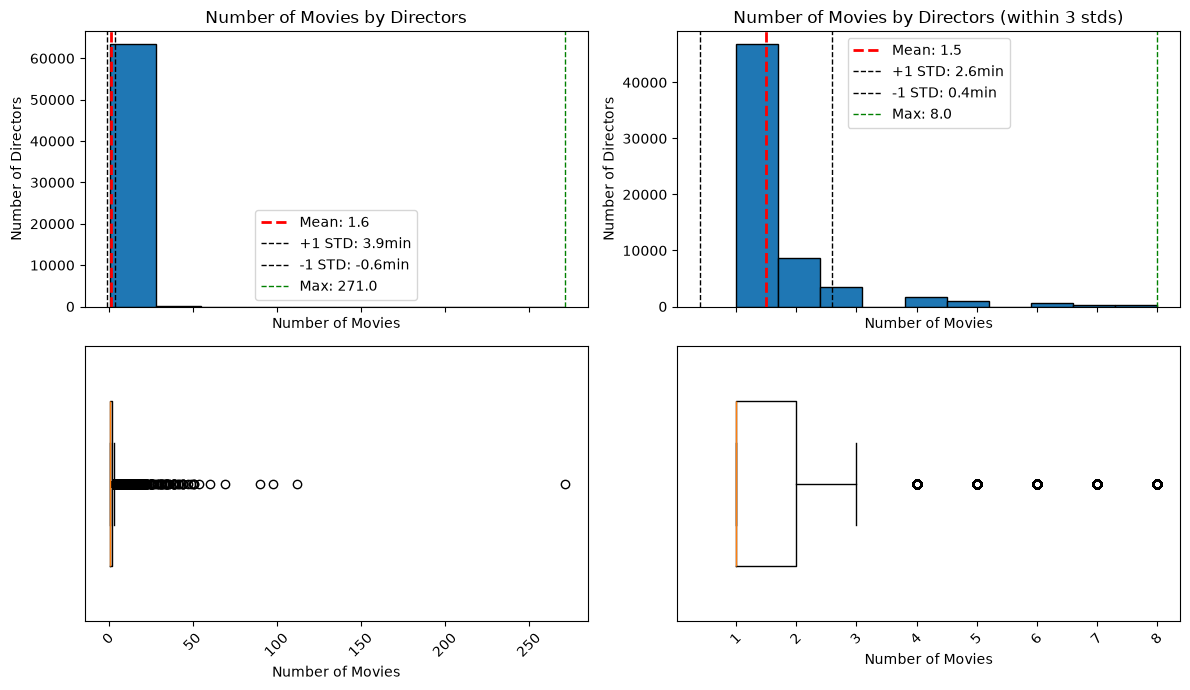

In [207]:
dir_count = basic_crew_merge.groupby('directors')['tconst'].count()

plots = [
    (dir_count, 'Number of Movies', 'Number of Movies by Directors'),
    (within_3_std(dir_count), 'Number of Movies', 'Number of Movies by Directors (within 3 stds)'),
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 7), 
    sharex = 'col'
)

for col, (data, xlabel, title) in enumerate(plots): 

    hist_ax = axes[0, col]
    box_ax = axes[1, col]
    mean, std, max = data.mean(), data.std(), data.max()

    # Histogram
    hist_ax.hist(data, bins=10, edgecolor='black')
    hist_ax.axvline(mean, color = 'red', linestyle = '--', linewidth = 2,
                    label = f"Mean: {mean:.1f}")
    hist_ax.axvline(mean + std, color='black', linestyle='--', linewidth=1,
                    label=f'+1 STD: {mean + std:.1f}{unit}')
    hist_ax.axvline(mean - std, color='black', linestyle='--', linewidth=1,
                    label=f'-1 STD: {mean - std:.1f}{unit}')
    hist_ax.axvline(max, color = 'green', linestyle = "--", linewidth = 1, 
                    label = f"Max: {max:.1f}")
    hist_ax.set_title(title)
    hist_ax.set_xlabel(xlabel)
    hist_ax.set_ylabel("Number of Directors")
    hist_ax.legend()

    box_ax.boxplot(data, orientation='horizontal', widths=0.6)
    box_ax.set_yticks([])
    box_ax.set_xlabel(xlabel)
    box_ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

### Result
It looks like most of the directors have made an average of 1.6 movies, which is lower than I expected, but the max was 271 movies by one director, which is much higher than I thought. It will be interesting to see where the spread lands after filtering based on reviews and actors. 

# Step 4
Now I want to read in the title ratings, and try to match that with some cast information. 

In [208]:
try: 
    ratings_filter_df = pd.read_csv("data/title_rating_filter.tsv", sep = "\t")
    print("\nFiltered DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
except: 
    title_ratings_df = pd.read_csv("data/title.ratings.tsv", sep = "\t")
    shape = title_ratings_df.shape
    print("Original DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
    print(title_ratings_df.isna().sum())
    ratings_filter_df = title_ratings_df.dropna()
    ratings_filter_df = pd.merge(basic_crew_merge['tconst'], ratings_filter_df, how = "inner", on = "tconst", )
    shape = ratings_filter_df.shape
    print("\nFiltered DF")
    print("Rows:", shape[0])
    print("Cols:", shape[1])
    ratings_filter_df.to_csv("data/title_rating_filter.tsv", sep = "\t", index = False)

ratings_filter_df.head()



Filtered DF
Rows: 103924
Cols: 9


,tconst,averageRating,numVotes
0,tt0015724,6.2,35
1,tt0057461,4.7,30
2,tt0065108,6.8,34
3,tt0065188,6.5,44
4,tt0065530,6.3,83


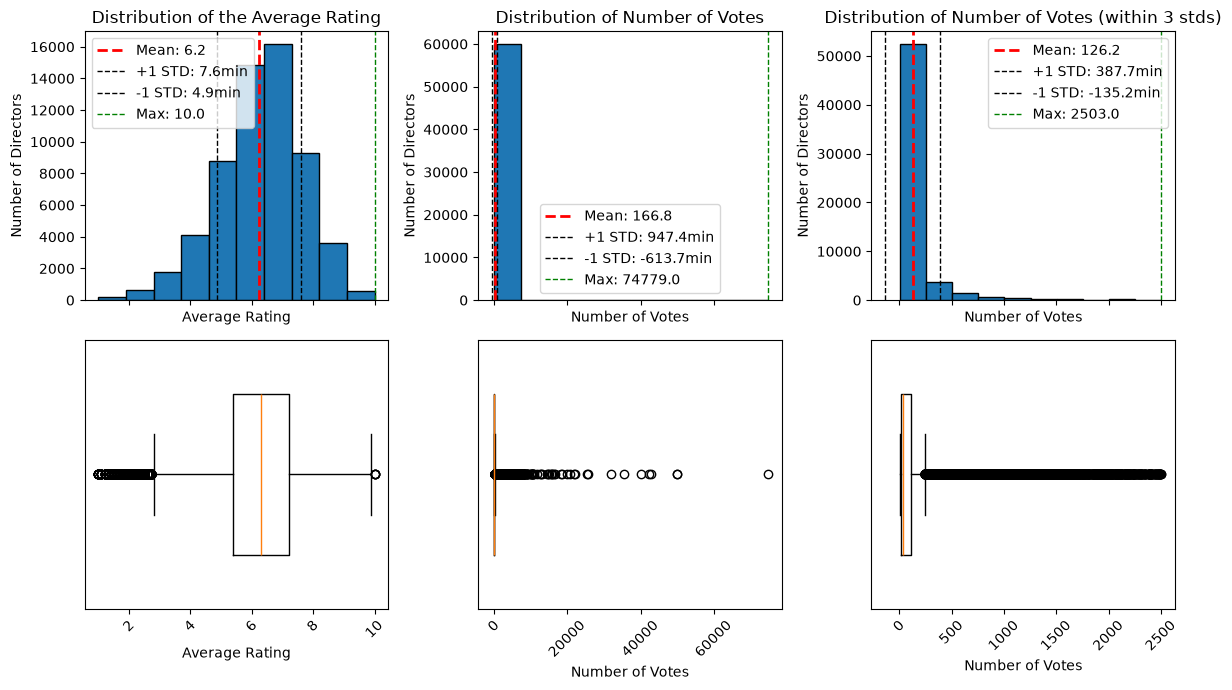

In [209]:
plots = [
    (ratings_filter_df['averageRating'], 'Average Rating', 'Distribution of the Average Rating'),
    (ratings_filter_df['numVotes'], 'Number of Votes', 'Distribution of Number of Votes'),
    (within_3_std(ratings_filter_df['numVotes']), 'Number of Votes', 'Distribution of Number of Votes (within 3 stds)'),
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(12, 7), 
    sharex = 'col'
)

for col, (data, xlabel, title) in enumerate(plots): 

    hist_ax = axes[0, col]
    box_ax = axes[1, col]
    mean, std, max = data.mean(), data.std(), data.max()

    # Histogram
    hist_ax.hist(data, bins=10, edgecolor='black')
    hist_ax.axvline(mean, color = 'red', linestyle = '--', linewidth = 2,
                    label = f"Mean: {mean:.1f}")
    hist_ax.axvline(mean + std, color='black', linestyle='--', linewidth=1,
                    label=f'+1 STD: {mean + std:.1f}{unit}')
    hist_ax.axvline(mean - std, color='black', linestyle='--', linewidth=1,
                    label=f'-1 STD: {mean - std:.1f}{unit}')
    hist_ax.axvline(max, color = 'green', linestyle = "--", linewidth = 1, 
                    label = f"Max: {max:.1f}")
    hist_ax.set_title(title)
    hist_ax.set_xlabel(xlabel)
    hist_ax.set_ylabel("Number of Directors")
    hist_ax.legend()

    box_ax.boxplot(data, orientation='horizontal', widths=0.6)
    box_ax.set_yticks([])
    box_ax.set_xlabel(xlabel)
    box_ax.tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()


### Result
What this tells me, is that the average rating is much more normally distributed (slight left skew) than any of the other values in this dataset, which is generally what I would expect. On average, a movie gets rated slightly above the random average (5 out of 10), and leans more upward (which makes sense because movies are supposed to be good). 
Another interesting part of this is the number of votes films are getting. It makes me curious to see if there is any impact on numVotes and the average rating. 

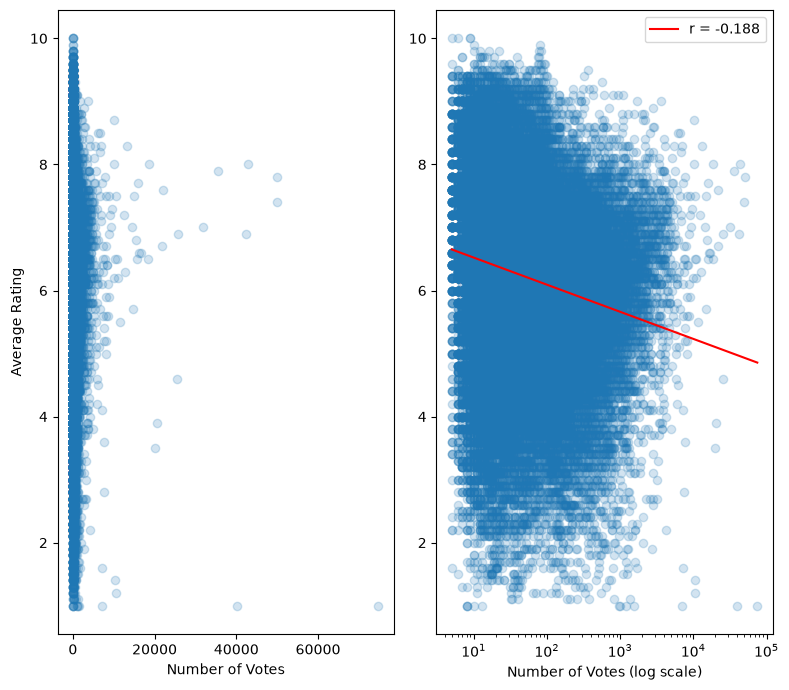

In [233]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(8, 7), 
    sharex = 'col'
)

norm_scat = axes[0]
norm_scat.scatter(ratings_filter_df['numVotes'], ratings_filter_df['averageRating'], alpha = 0.2)
norm_scat.set_xlabel("Number of Votes")
norm_scat.set_ylabel("Average Rating")

log_scat = axes[1]
log_scat.scatter(ratings_filter_df['numVotes'], ratings_filter_df['averageRating'], alpha = 0.2)
log_scat.set_xlabel("Number of Votes (log scale)")
log_scat.set_xscale('log')

log_reg = linregress(
    np.log10(ratings_filter_df['numVotes']),
    ratings_filter_df['averageRating']
)

x_log = np.logspace(
    np.log10(ratings_filter_df['numVotes'].min()),
    np.log10(ratings_filter_df['numVotes'].max()),
    100
)

y_log = (
    log_reg.slope * np.log10(x_log)
    + log_reg.intercept
)

log_scat.plot(
    x_log,
    y_log,
    color='red',
    label=f"r = {log_reg.rvalue:.3f}"
)

log_scat.legend()

plt.tight_layout()
plt.show()

### Result
There doesn't seem to be much of a relationship between the number of votes and the average rating. Because numVotes is so right skewed I used a log transform, and still only got an r-value of -0.188, which is very weak. 

## Step 5
I want to merge the ratings data with the rest of the movie data and see if we can learn anything from the movie data. Before I merge the last cut I want to make it to only select movies with a rating that has an above average number of votes. 

In [223]:
shape = ratings_filter_df.shape
print("Before Mean Filter")
print("Rows:", shape[0])
print("Cols:", shape[1])

mask = (ratings_filter_df['numVotes'] >= 126)

ratings_filter_df_mean = ratings_filter_df.loc[mask, :]
shape = ratings_filter_df_mean.shape
print("\nAfter Mean Filter")
print("Rows:", shape[0])
print("Cols:", shape[1])

title_rating_full = pd.merge(basic_crew_merge, ratings_filter_df_mean, how = "inner", on = "tconst")
shape = title_rating_full.shape
print("\nAfter Merge")
print("Rows:", shape[0])
print("Cols:", shape[1])
title_rating_full.head()

Before Mean Filter
Rows: 60026
Cols: 3

After Mean Filter
Rows: 13777
Cols: 3

After Merge
Rows: 13777
Cols: 11


,tconst,titleType,primaryTitle,isAdult,startYear,runtimeMinutes,genres,directors,writers,averageRating,numVotes
0,tt0066151,movie,Ninja Destroyer,0,1986,92.0,"Action,Adventure",nm0061792,"nm0007554,nm0061792",3.7,129
1,tt0075211,movie,Shocking Asia II: The Last Taboos,0,1985,90.0,"Documentary,Horror",nm0288975,nm0288975,4.9,303
2,tt0078791,movie,Aquella casa en las afueras,0,1980,95.0,"Horror,Thriller",nm0554632,"nm0161728,nm0191186,nm0554632,nm0559120,nm0838...",5.7,227
3,tt0078799,movie,"Artista, dolarii si Ardelenii",0,1980,74.0,"Drama,Western",nm0894758,nm0691489,7.3,502
4,tt0078853,movie,Carnapping,0,1980,89.0,"Comedy,Crime",nm0926872,"nm0237252,nm4864364,nm0926872",6.1,338


## Step 6
Now that I have a final result, I want to see if there is any discernable relationship between different movie characteristics and their average rating. 

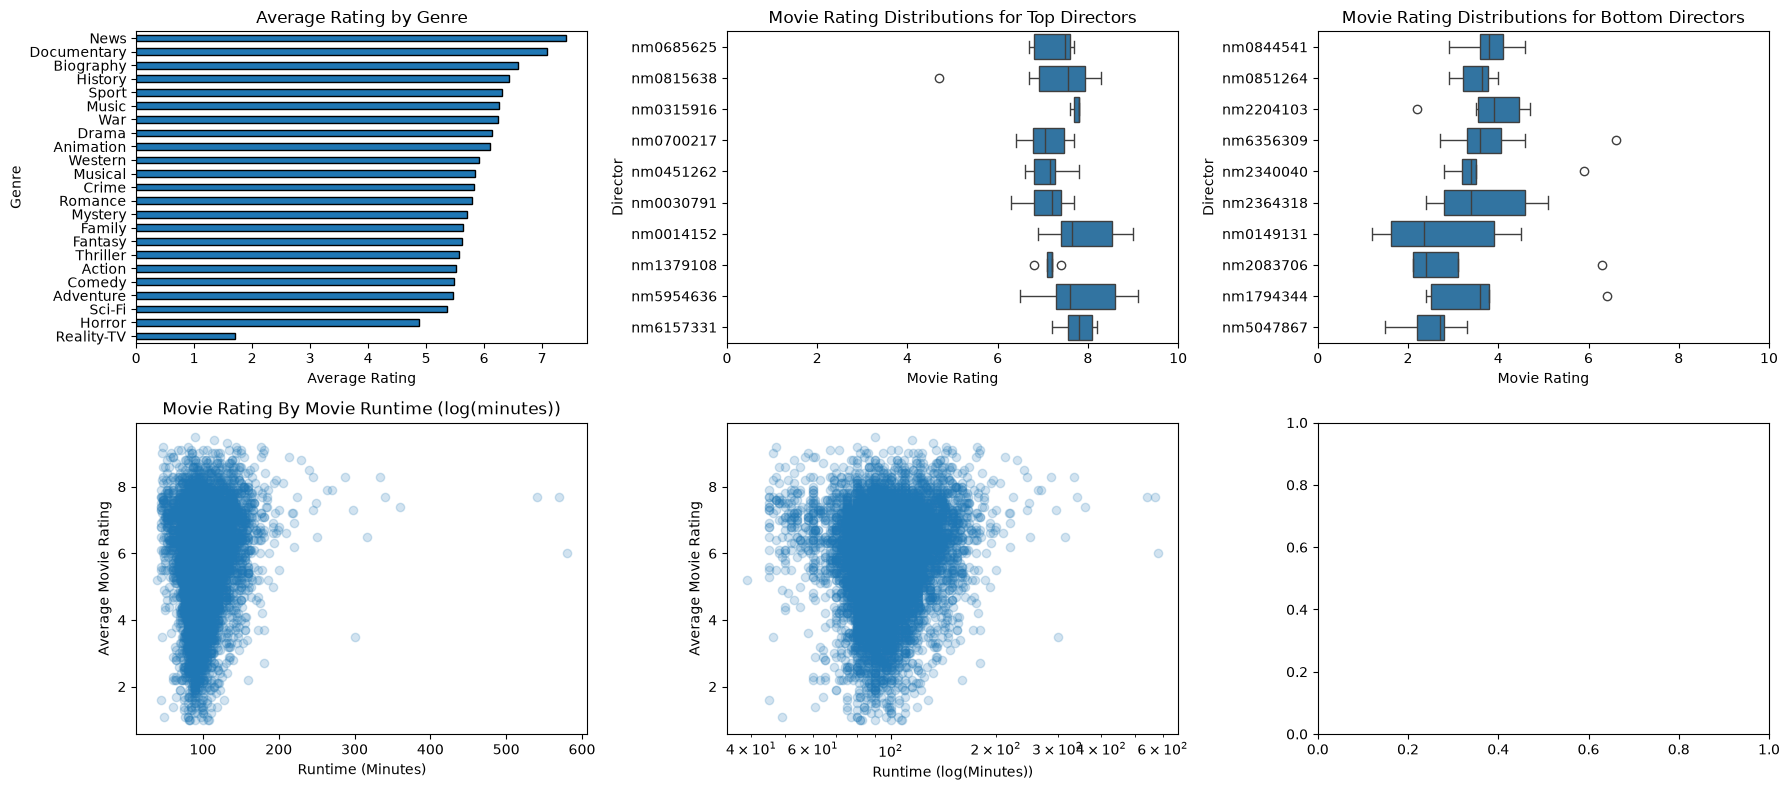

In [235]:
genre_df = title_rating_full[['genres', 'averageRating']].assign(
    genres = title_rating_full['genres'].str.split(',')
).explode('genres')

genre_avg = genre_df.groupby('genres')['averageRating'].mean().sort_values(ascending=True)
dir_mask = ~title_rating_full['directors'].str.contains(',')
top_dir = title_rating_full.loc[dir_mask, ['directors', 'averageRating']].groupby('directors')['averageRating'].agg(['mean', 'count']).query('count >= 5').sort_values('mean', ascending= False).head(10).reset_index()
bot_dir = title_rating_full.loc[dir_mask, ['directors', 'averageRating']].groupby('directors')['averageRating'].agg(['mean', 'count']).query('count >= 5').sort_values('mean', ascending= True).head(10).reset_index()

top_dir_movies = pd.merge(title_rating_full.loc[:, ['tconst', 'averageRating', 'directors']], top_dir.loc[:, 'directors'], how = 'inner', on = 'directors')

bot_dir_movies = pd.merge(title_rating_full.loc[:, ['tconst', 'averageRating', 'directors']], bot_dir.loc[:, 'directors'], how = 'inner', on = 'directors')


fig, axes = plt.subplots(2, 3, figsize = (18, 8))

genre_avg.plot.barh(
    ax=axes[0, 0],
    edgecolor='black',
    title='Average Rating by Genre'
)

sns.boxplot(
    data=top_dir_movies,
    x='averageRating',
    y='directors',
    ax=axes[0, 1]
)
axes[0, 1].set_xlim(left = 0, right = 10)

sns.boxplot(
    data = bot_dir_movies, 
    x = 'averageRating', 
    y = 'directors', 
    ax = axes[0, 2], 
)
axes[0, 2].set_xlim(left = 0, right = 10)
axes[0, 2].set_title('Movie Rating Distributions for Bottom Directors')
axes[0, 2].set_xlabel('Movie Rating')
axes[0, 2].set_ylabel('Director')

axes[0, 0].set_xlabel('Average Rating')
axes[0, 0].set_ylabel('Genre')

axes[0, 1].set_title('Movie Rating Distributions for Top Directors')
axes[0, 1].set_xlabel('Movie Rating')
axes[0, 1].set_ylabel('Director')


time_scat = axes[1, 0]
time_scat.scatter(y = title_rating_full['averageRating'], x = title_rating_full['runtimeMinutes'], alpha = 0.2)
time_scat.set_title('Movie Rating By Movie Runtime (Minutes)')
time_scat.set_xlabel("Runtime (Minutes)")
time_scat.set_ylabel("Average Movie Rating")

time_scat_log = axes[1, 1]
time_scat_log.scatter(x = title_rating_full['runtimeMinutes'], y = title_rating_full['averageRating'], alpha = 0.2)
time_scat_log.set_xscale('log')
time_scat.set_title('Movie Rating By Movie Runtime (log(minutes))')
time_scat_log.set_xlabel("Runtime (log(Minutes))")
time_scat_log.set_ylabel("Average Movie Rating")


plt.tight_layout()
plt.show()